In [1]:
import os
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score


In [2]:
warnings.filterwarnings("ignore")
np.random.seed(42)
sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("Mall_Customers.csv")

In [4]:
print("Dataset Information")
df.info()

print("\nDescriptive Statistics")
display(df.describe(include="all").T)

print("\nMissing Values")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types")
display(df.dtypes.to_frame("Data Type"))


Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Descriptive Statistics


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0



Missing Values


,Missing Values
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Duplicate Rows: 0

Data Types


,Data Type
CustomerID,int64
Gender,str
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [5]:
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numeric_cols)

for col in categorical_cols:
    print(f"\nValue Counts: {col}")
    display(df[col].value_counts(dropna=False).to_frame("Count"))



Categorical Columns: ['Gender']
Numerical Columns: ['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Value Counts: Gender


,Count
Gender,
Female,112
Male,88


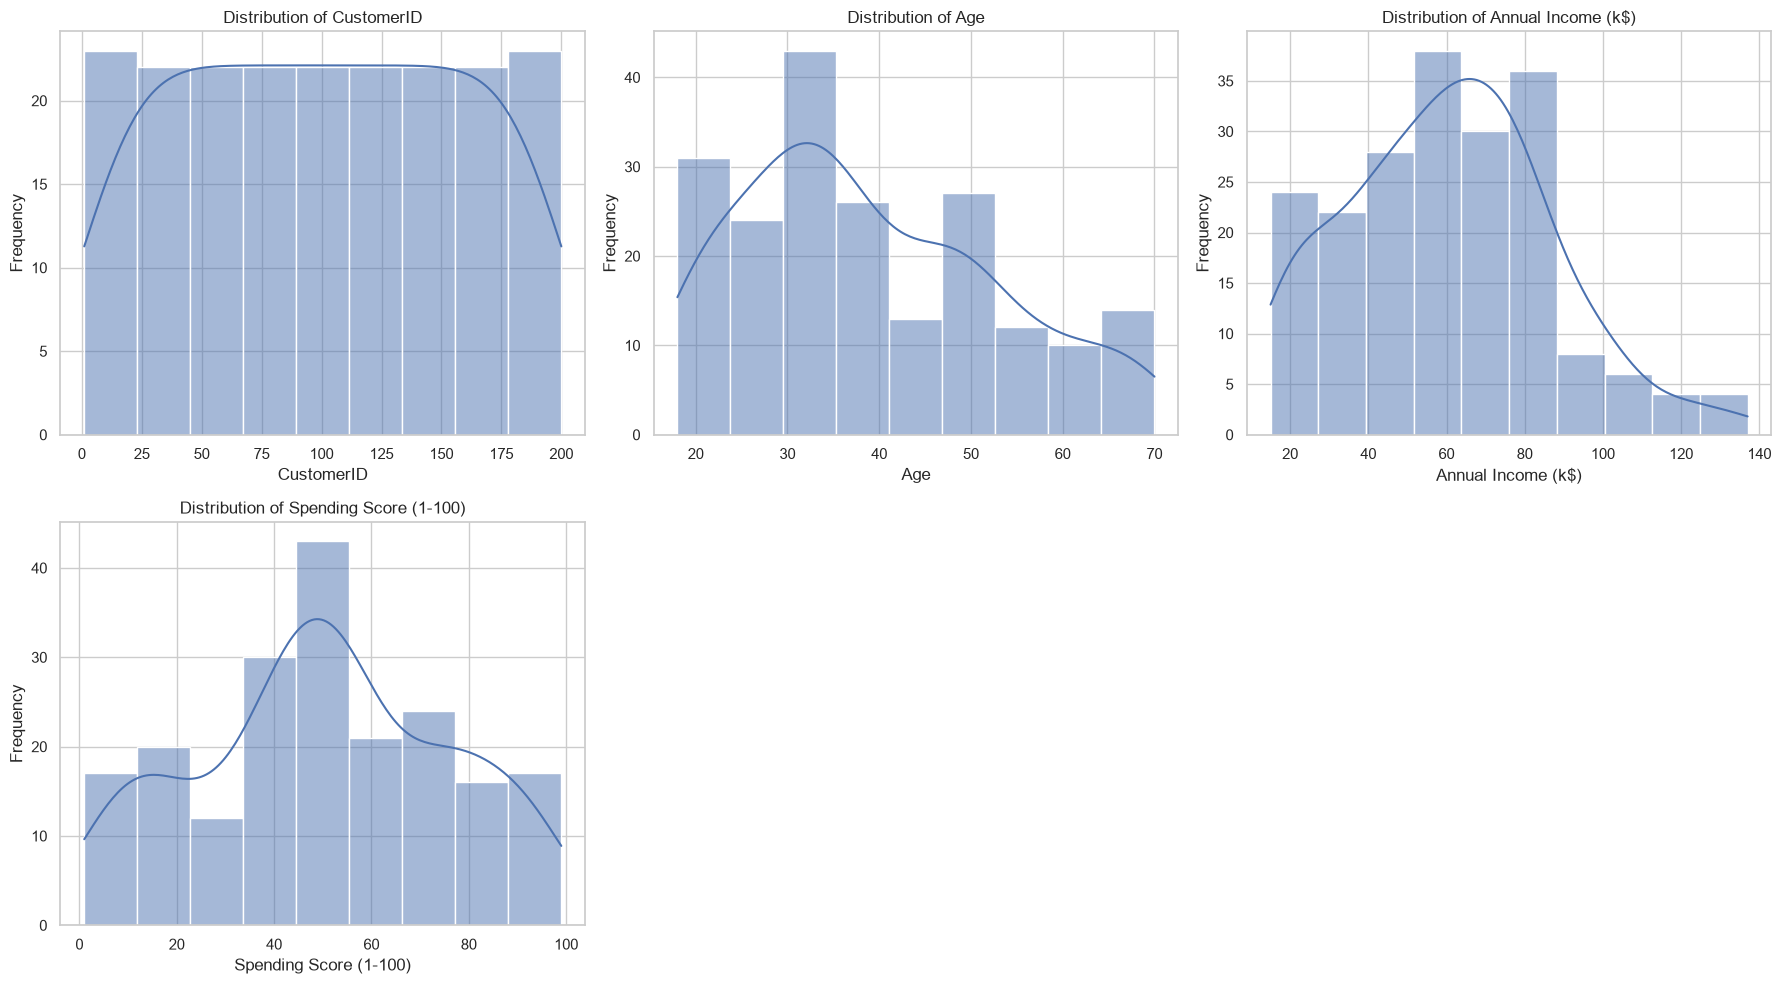

In [6]:
if len(numeric_cols) > 0:
    rows = int(np.ceil(len(numeric_cols) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(numeric_cols):
        sns.histplot(df[col], kde=True, ax=axes[i])
        axes[i].set_title(f"Distribution of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")

    for i in range(len(numeric_cols), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


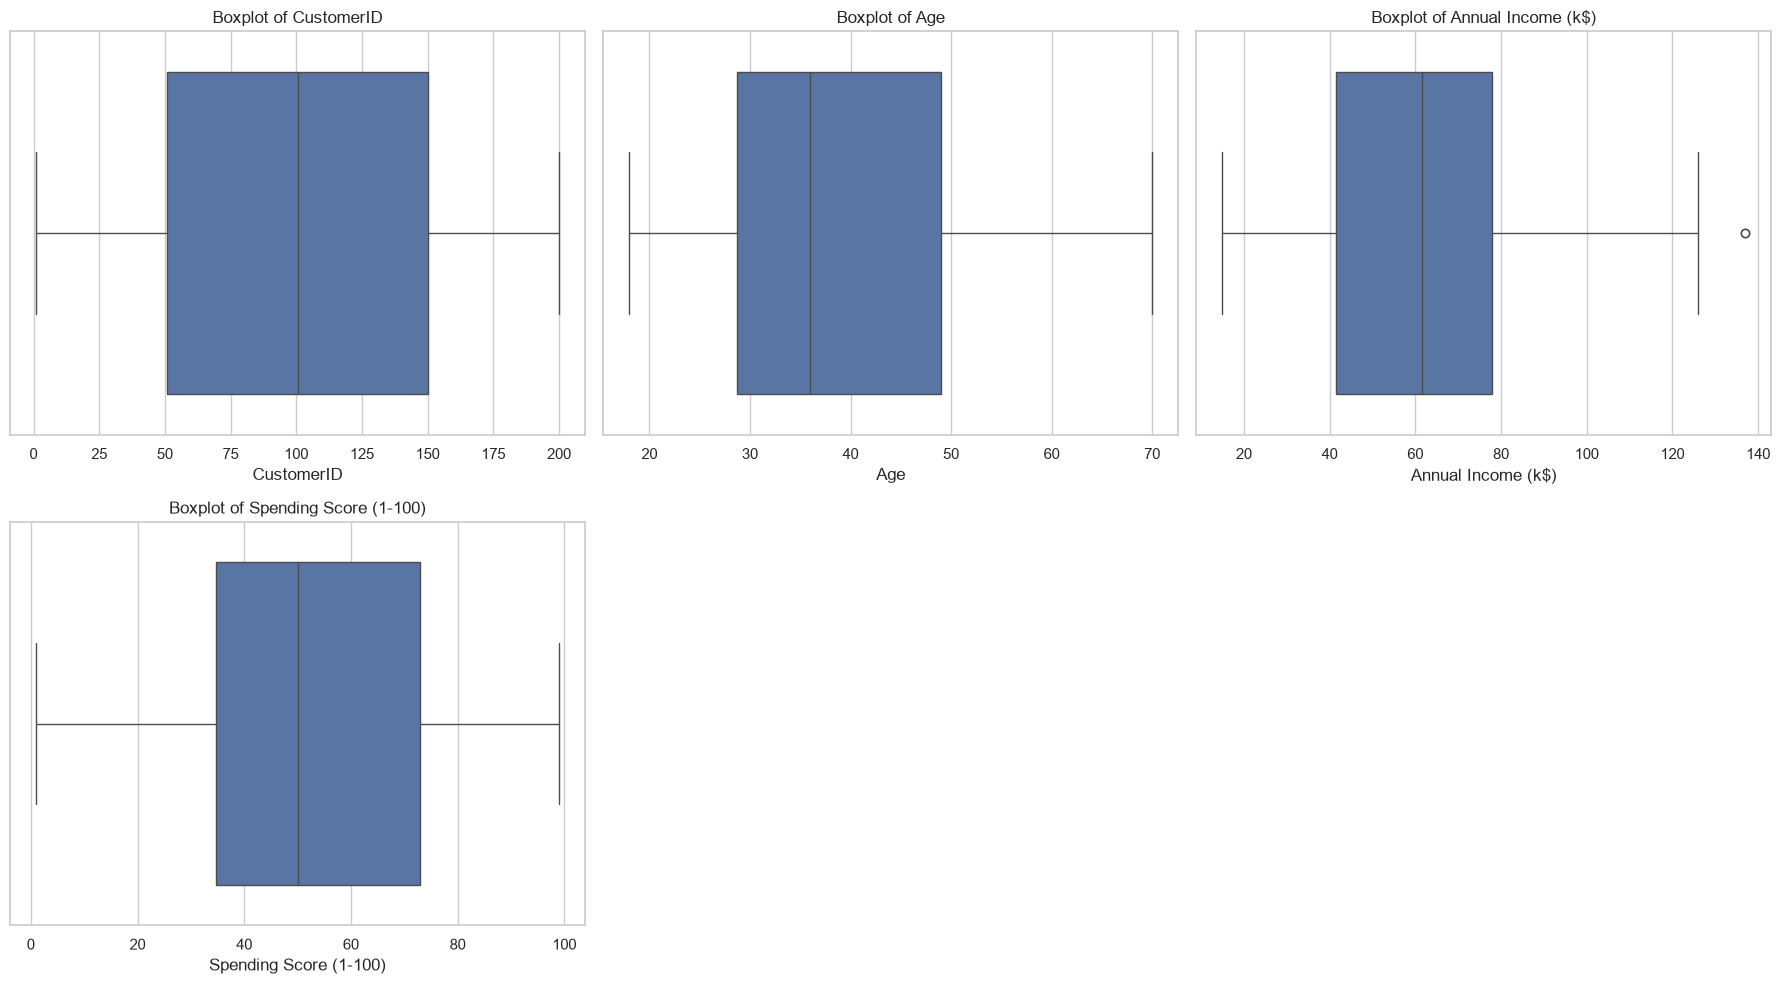

In [7]:
if len(numeric_cols) > 0:
    rows = int(np.ceil(len(numeric_cols) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(numeric_cols):
        sns.boxplot(x=df[col], ax=axes[i])
        axes[i].set_title(f"Boxplot of {col}")

    for i in range(len(numeric_cols), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


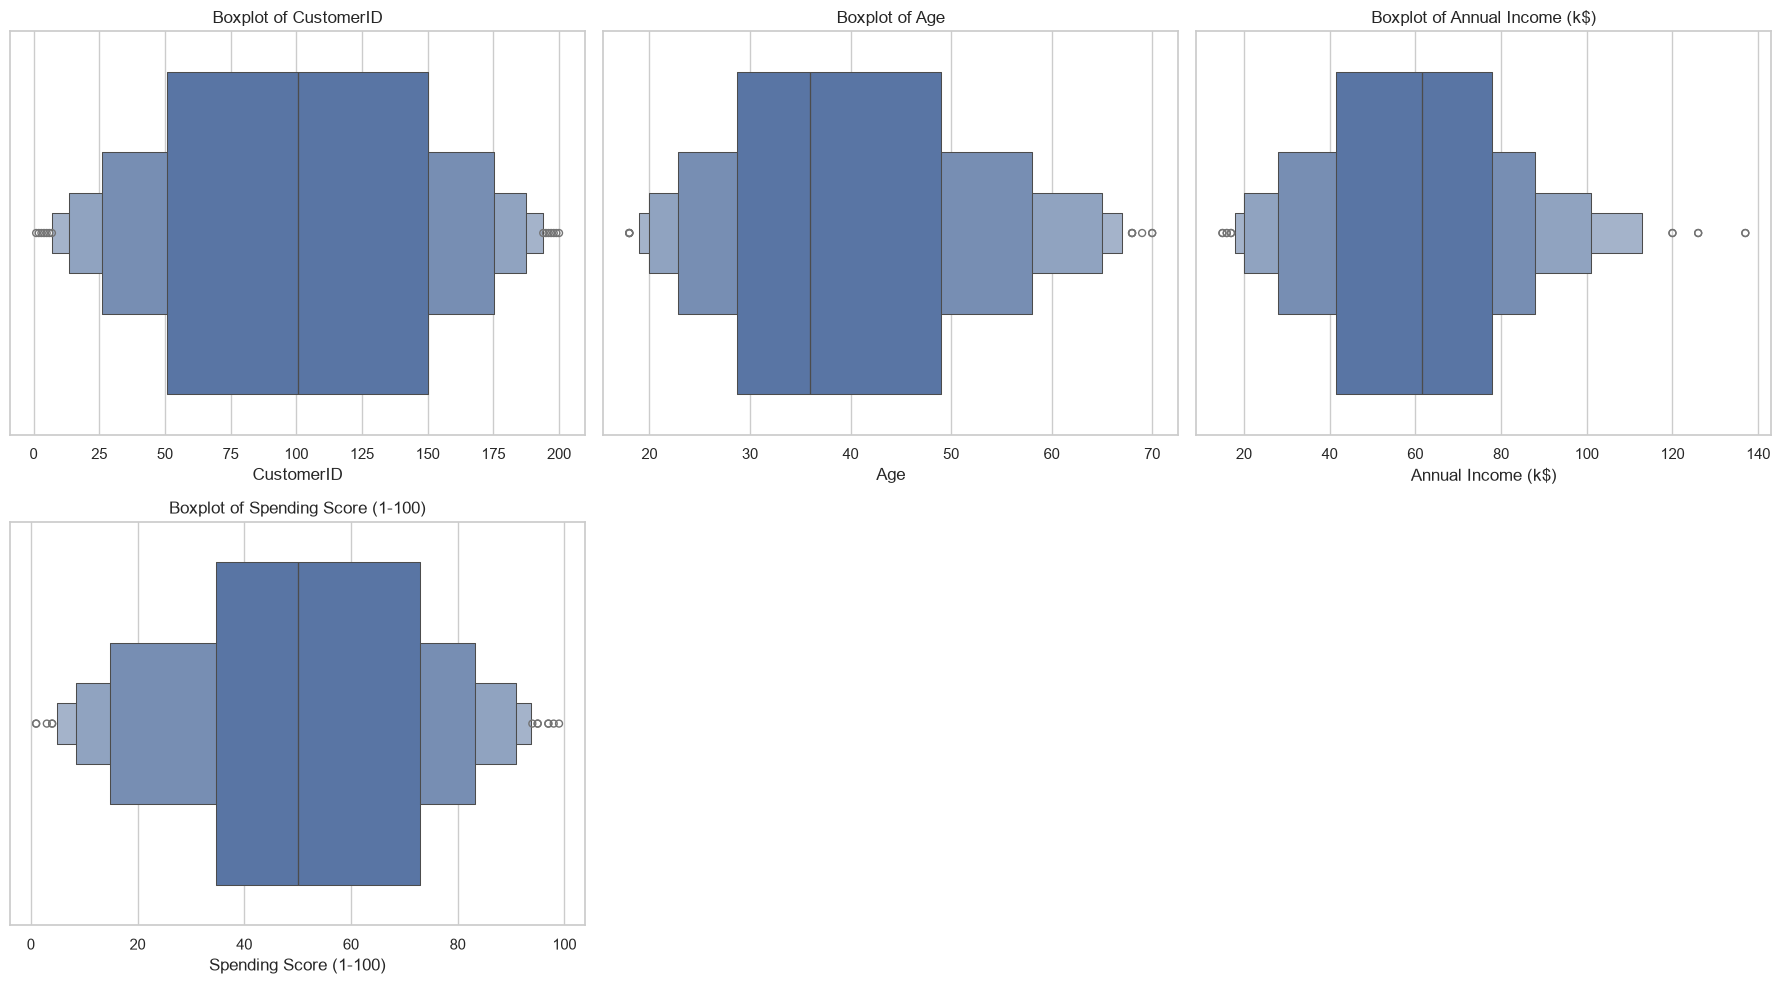

In [8]:
if len(numeric_cols) > 0:
    rows = int(np.ceil(len(numeric_cols) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(numeric_cols):
        sns.boxenplot(x=df[col], ax=axes[i])
        axes[i].set_title(f"Boxplot of {col}")

    for i in range(len(numeric_cols), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


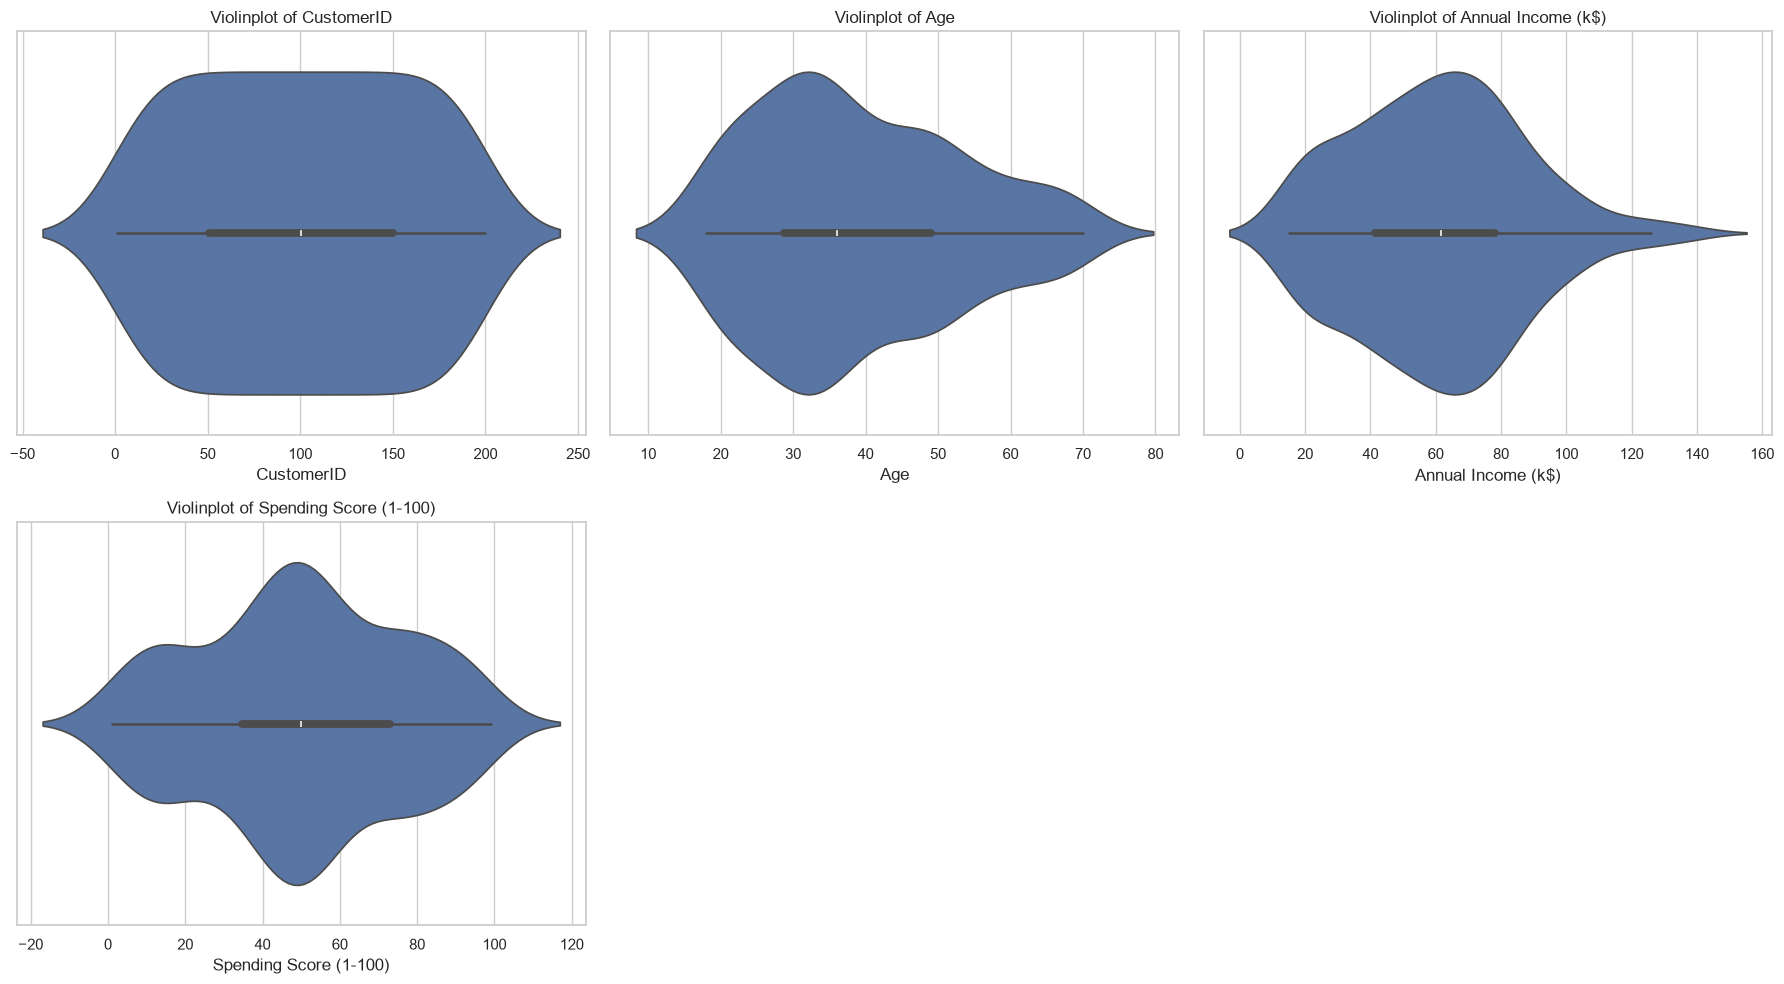

In [9]:
if len(numeric_cols) > 0:
    rows = int(np.ceil(len(numeric_cols) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(numeric_cols):
        sns.violinplot(x=df[col], ax=axes[i])
        axes[i].set_title(f"Violinplot of {col}")

    for i in range(len(numeric_cols), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


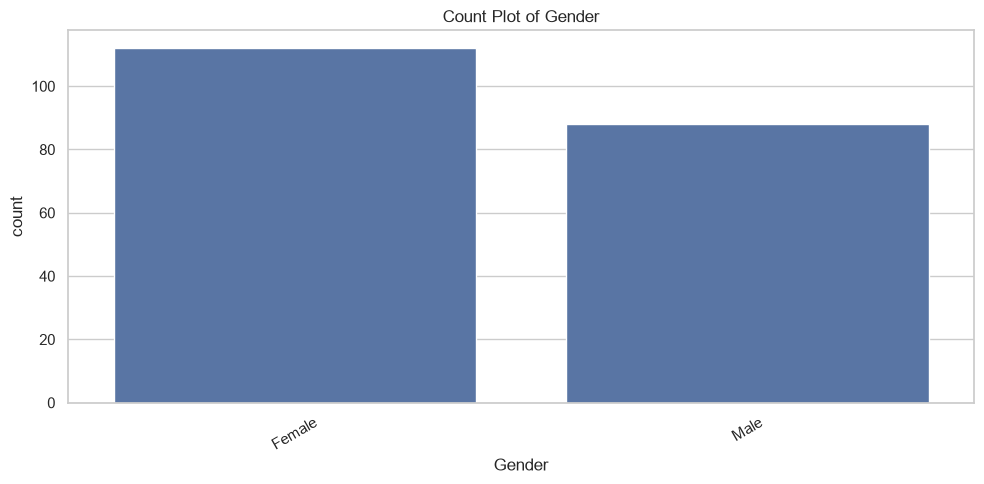

In [10]:
for col in categorical_cols:
    if df[col].nunique(dropna=True) <= 20:
        plt.figure(figsize=(10, 5))
        order = df[col].value_counts(dropna=False).index
        sns.countplot(data=df, x=col, order=order)
        plt.title(f"Count Plot of {col}")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()


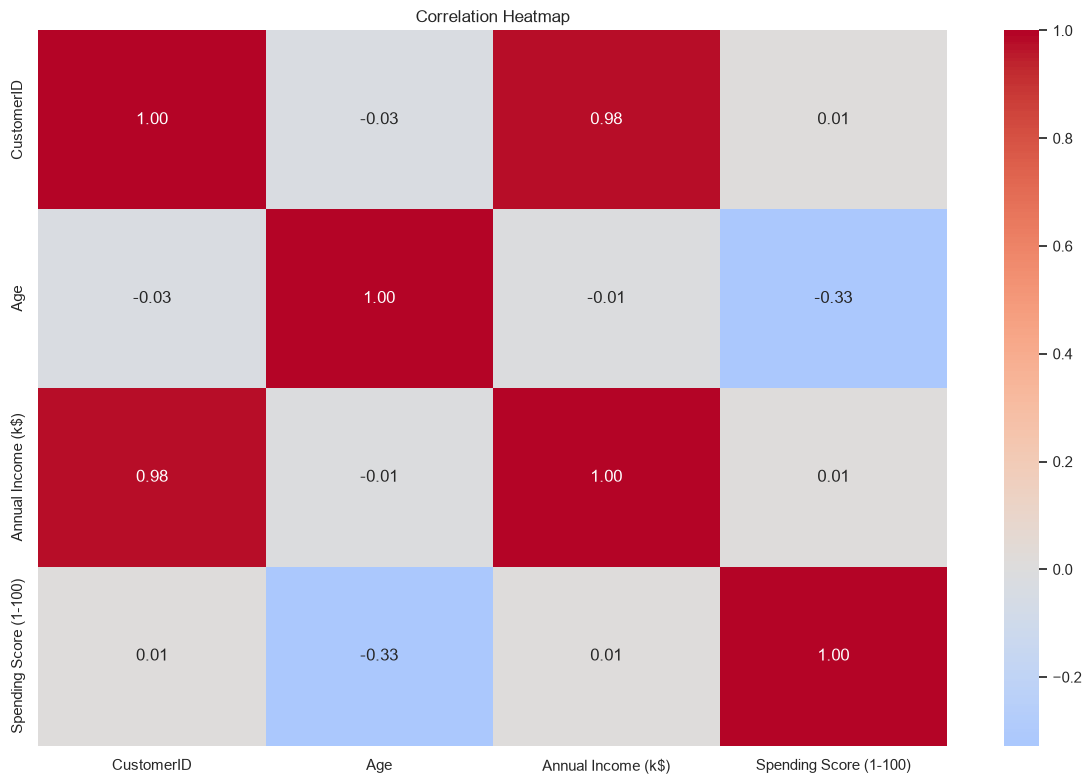

In [11]:
if len(numeric_cols) >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        df[numeric_cols].corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()


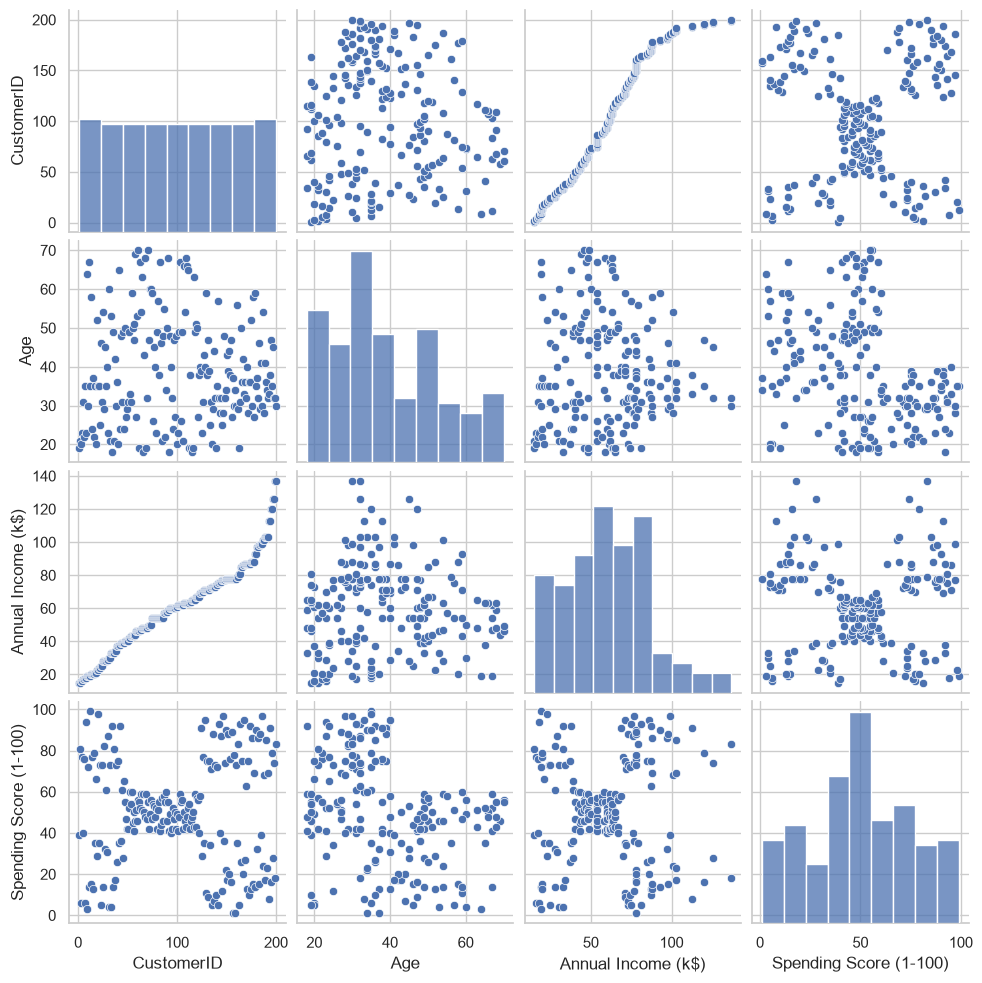

In [12]:
if len(numeric_cols) >= 2:
    sns.pairplot(df[numeric_cols].dropna())
    plt.show()


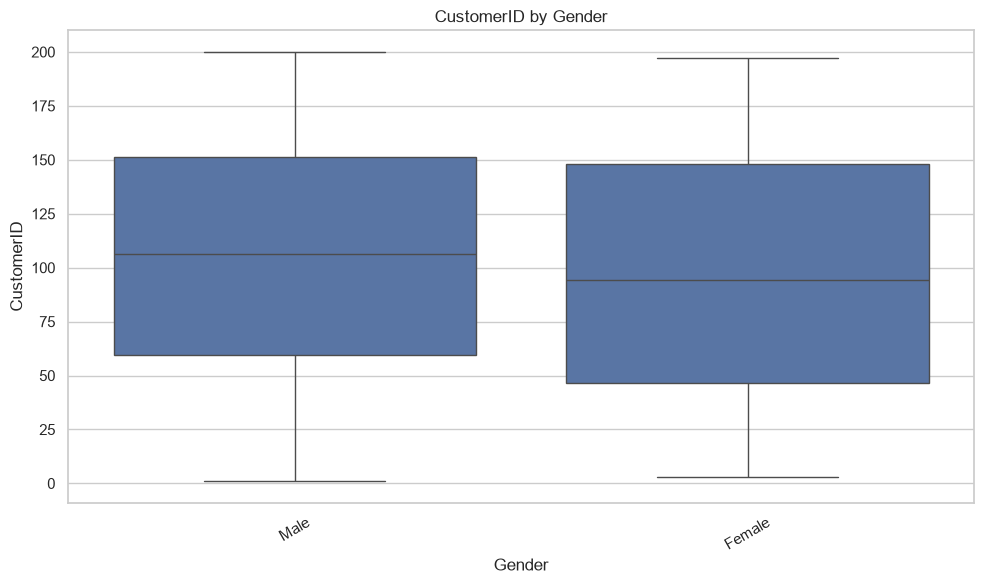

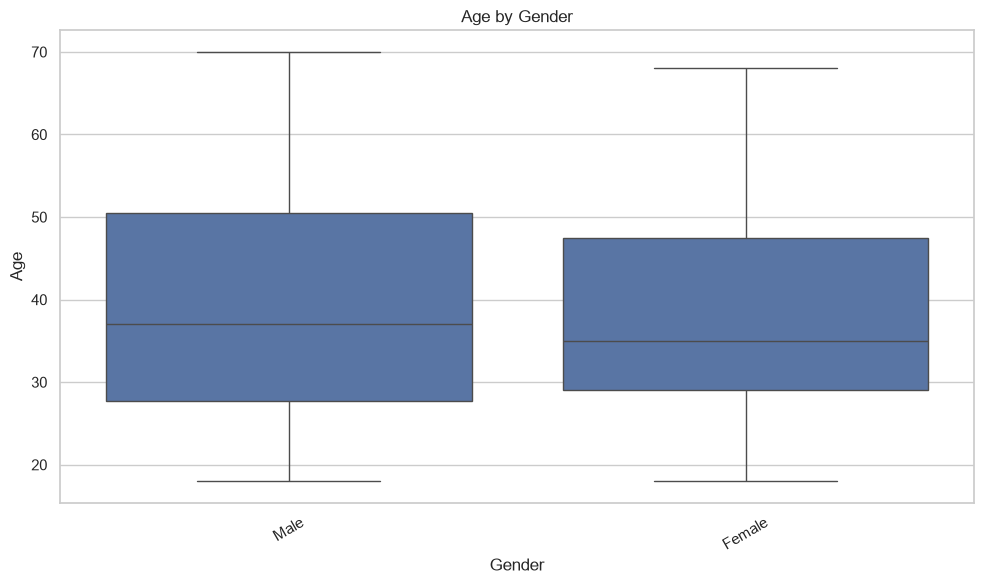

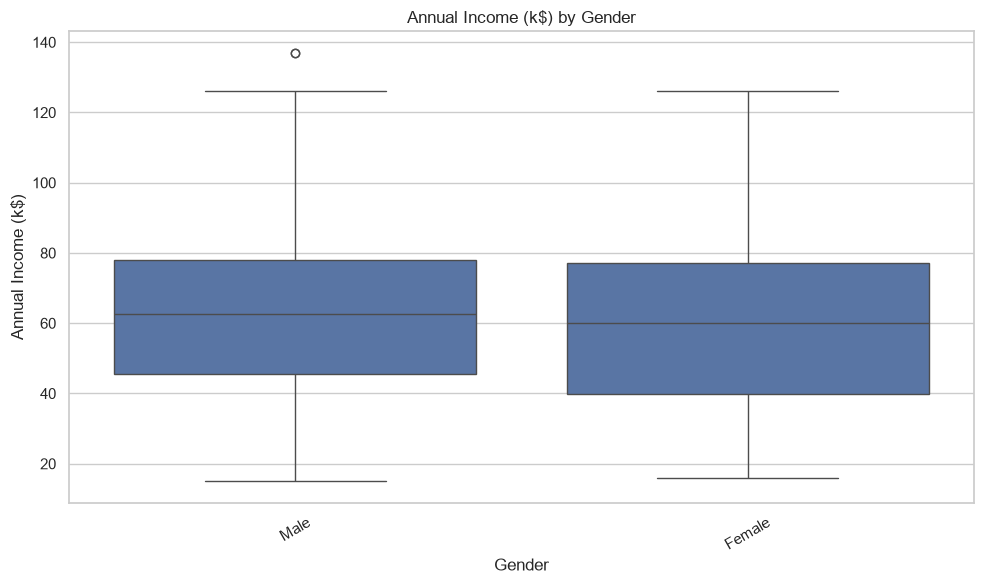

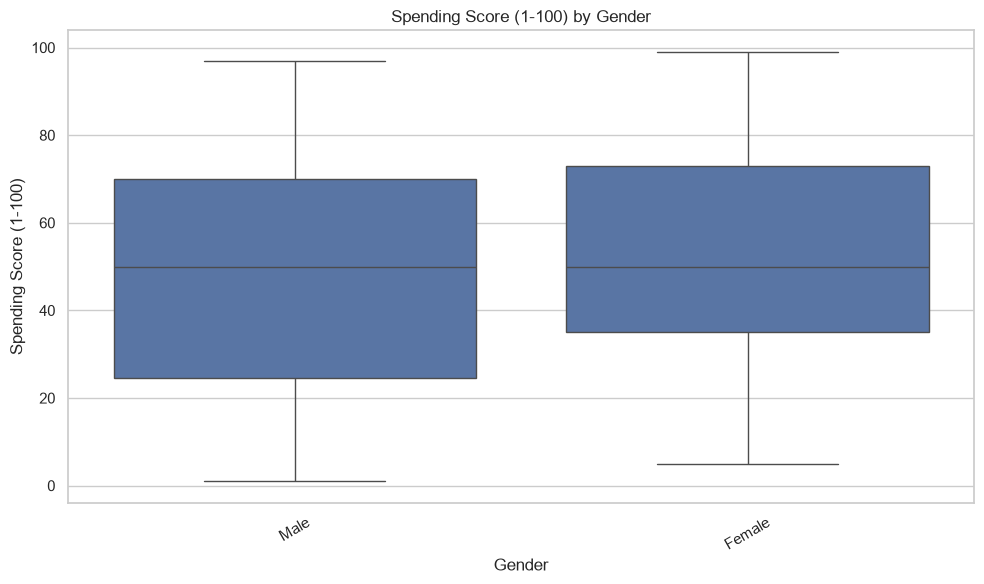

In [13]:
for col in categorical_cols:
    for num_col in numeric_cols:
        if df[col].nunique(dropna=True) <= 10:
            plt.figure(figsize=(10, 6))
            sns.boxplot(data=df, x=col, y=num_col)
            plt.title(f"{num_col} by {col}")
            plt.xticks(rotation=30)
            plt.tight_layout()
            plt.show()


In [14]:
work_df = df.copy()

id_like_cols = []

for col in work_df.columns:
    unique_count = work_df[col].nunique(dropna=True)
    if unique_count == len(work_df):
        id_like_cols.append(col)

id_names = [
    "customerid",
    "customer_id",
    "customer id",
    "id",
    "unnamed: 0"
]

drop_cols = []

for col in work_df.columns:
    if col.lower().strip() in id_names:
        drop_cols.append(col)

for col in id_like_cols:
    if col not in drop_cols:
        drop_cols.append(col)

work_df = work_df.drop(columns=drop_cols, errors="ignore")

numeric_features = work_df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = work_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Dropped Identifier Columns:", drop_cols)
print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

if len(numeric_features) == 0:
    raise ValueError("No numerical features available for K-Means clustering.")


Dropped Identifier Columns: ['CustomerID']
Numerical Features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Categorical Features: ['Gender']


In [15]:
X_numeric = work_df[numeric_features].copy()

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_numeric)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=numeric_features
)

print("Processed Feature Matrix Shape:", X_scaled.shape)
display(scaled_df.head())


Processed Feature Matrix Shape: (200, 3)


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


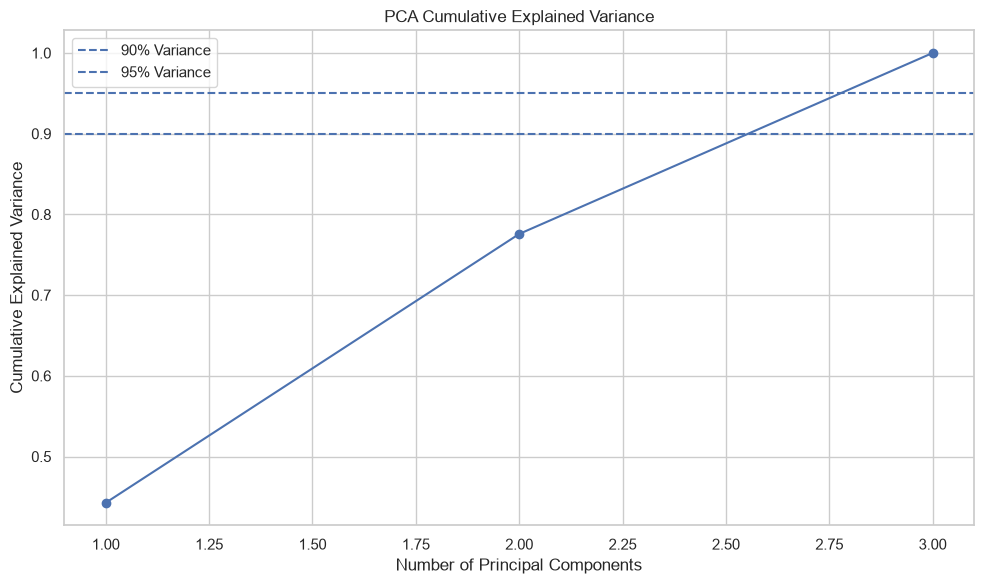

In [16]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(0.90, linestyle="--", label="90% Variance")
plt.axhline(0.95, linestyle="--", label="95% Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()


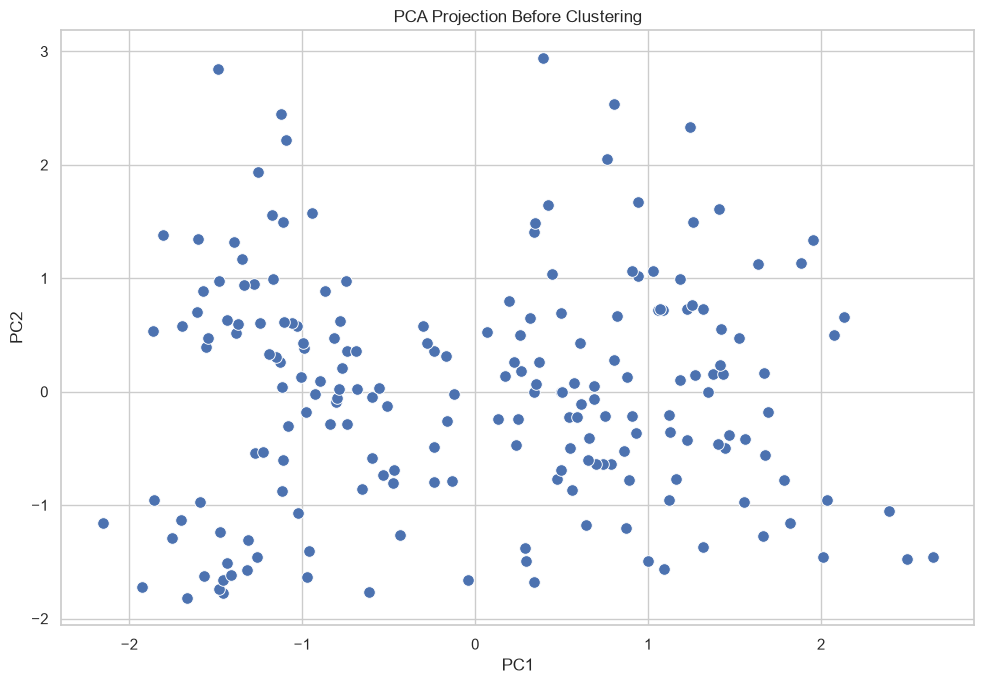

In [17]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    s=70
)
plt.title("PCA Projection Before Clustering")
plt.tight_layout()
plt.show()










In [18]:
k_values = range(2, 11)

inertia_values = []
silhouette_values = []
calinski_values = []
davies_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )
    calinski_values.append(
        calinski_harabasz_score(X_scaled, labels)
    )
    davies_values.append(
        davies_bouldin_score(X_scaled, labels)
    )

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values,
    "Calinski-Harabasz Index": calinski_values,
    "Davies-Bouldin Index": davies_values
})

display(k_results)


,K,Inertia,Silhouette Score,Calinski-Harabasz Index,Davies-Bouldin Index
0,2,389.386189,0.335472,107.095567,1.260682
1,3,295.212246,0.357793,101.694947,1.050270
2,4,205.225147,0.403958,125.676397,0.930796
3,5,168.247580,0.416643,125.100940,0.874551
4,6,133.868334,0.427428,135.102217,0.827743
5,7,117.011555,0.417232,132.774309,0.793467
6,8,103.828578,0.408681,131.074446,0.889278
7,9,92.349458,0.420074,131.242316,0.854109
8,10,81.987052,0.397284,133.384828,0.905614


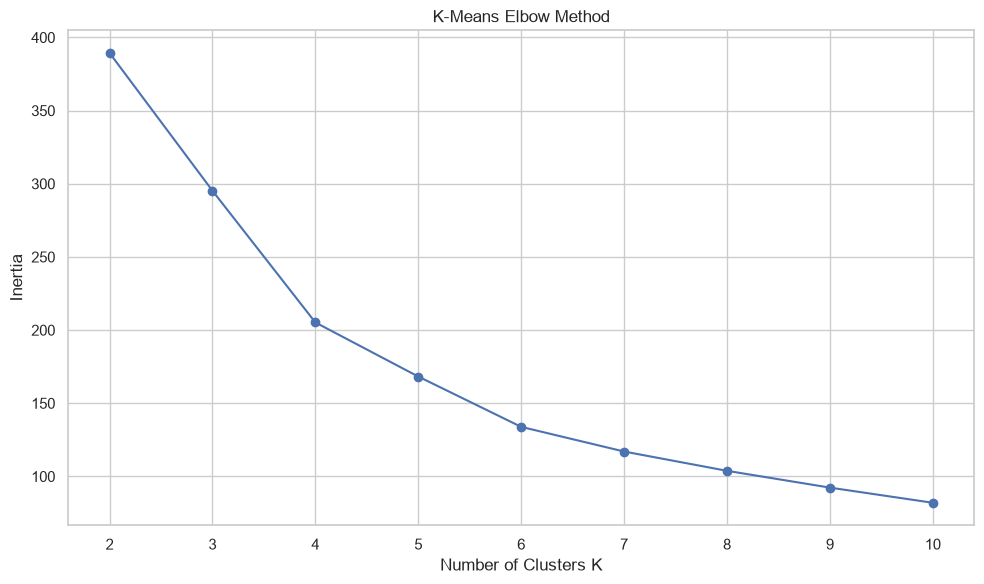

In [19]:
plt.figure(figsize=(10, 6))
plt.plot(
    k_results["K"],
    k_results["Inertia"],
    marker="o"
)
plt.xlabel("Number of Clusters K")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


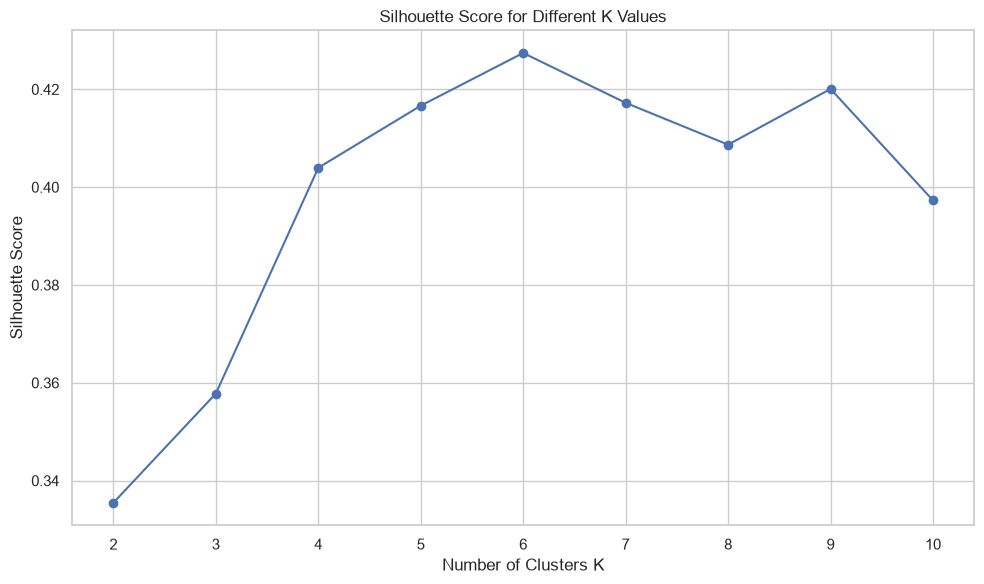

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(
    k_results["K"],
    k_results["Silhouette Score"],
    marker="o"
)
plt.xlabel("Number of Clusters K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


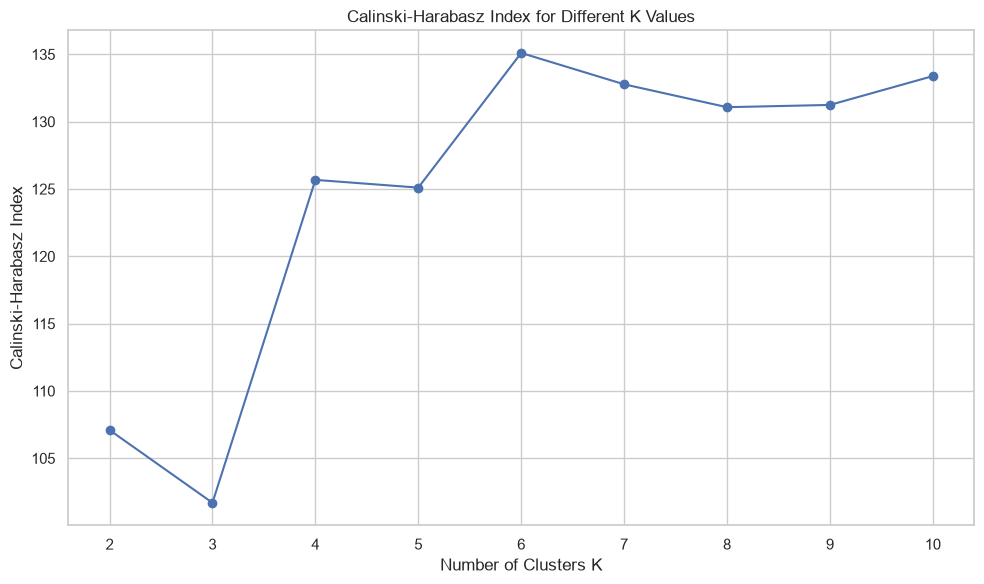

In [21]:
plt.figure(figsize=(10, 6))
plt.plot(
    k_results["K"],
    k_results["Calinski-Harabasz Index"],
    marker="o"
)
plt.xlabel("Number of Clusters K")
plt.ylabel("Calinski-Harabasz Index")
plt.title("Calinski-Harabasz Index for Different K Values")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


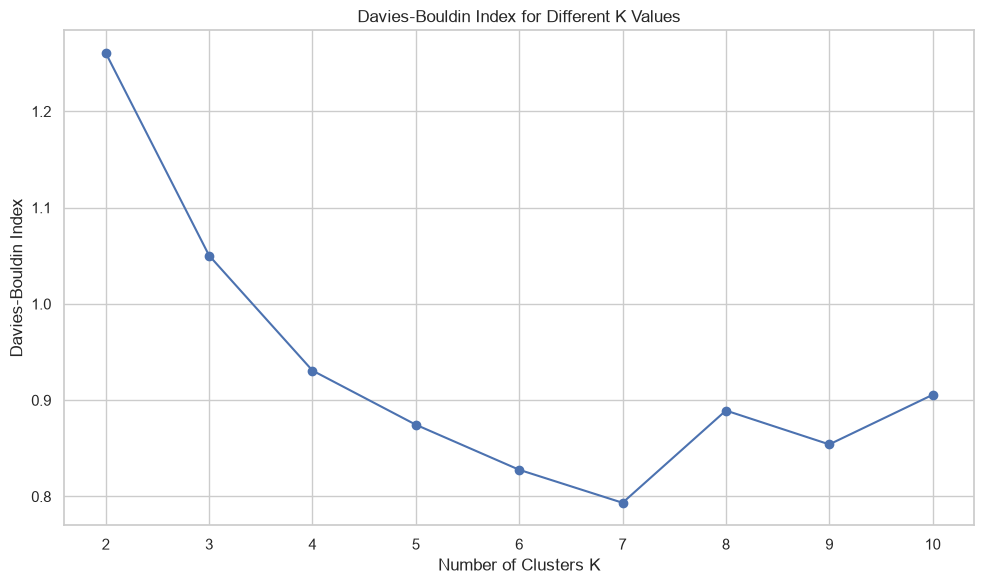

In [22]:
plt.figure(figsize=(10, 6))
plt.plot(
    k_results["K"],
    k_results["Davies-Bouldin Index"],
    marker="o"
)
plt.xlabel("Number of Clusters K")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index for Different K Values")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


In [23]:
best_k_silhouette = int(
    k_results.loc[
        k_results["Silhouette Score"].idxmax(),
        "K"
    ]
)

best_k_calinski = int(
    k_results.loc[
        k_results["Calinski-Harabasz Index"].idxmax(),
        "K"
    ]
)

best_k_davies = int(
    k_results.loc[
        k_results["Davies-Bouldin Index"].idxmin(),
        "K"
    ]
)

print("Best K by Silhouette Score:", best_k_silhouette)
print("Best K by Calinski-Harabasz Index:", best_k_calinski)
print("Best K by Davies-Bouldin Index:", best_k_davies)

final_k = best_k_silhouette
print("Selected Final K:", final_k)


Best K by Silhouette Score: 6
Best K by Calinski-Harabasz Index: 6
Best K by Davies-Bouldin Index: 7
Selected Final K: 6


In [25]:
kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=20
)

cluster_labels = kmeans.fit_predict(X_scaled)

df_clustered = df.copy()
df_clustered["Cluster"] = cluster_labels

print("Final K:", final_k)
display(df_clustered.head())


Final K: 6


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,5
3,4,Female,23,16,77,2
4,5,Female,31,17,40,5


,Customer Count
Cluster,
0,33
1,45
2,24
3,39
4,38
5,21


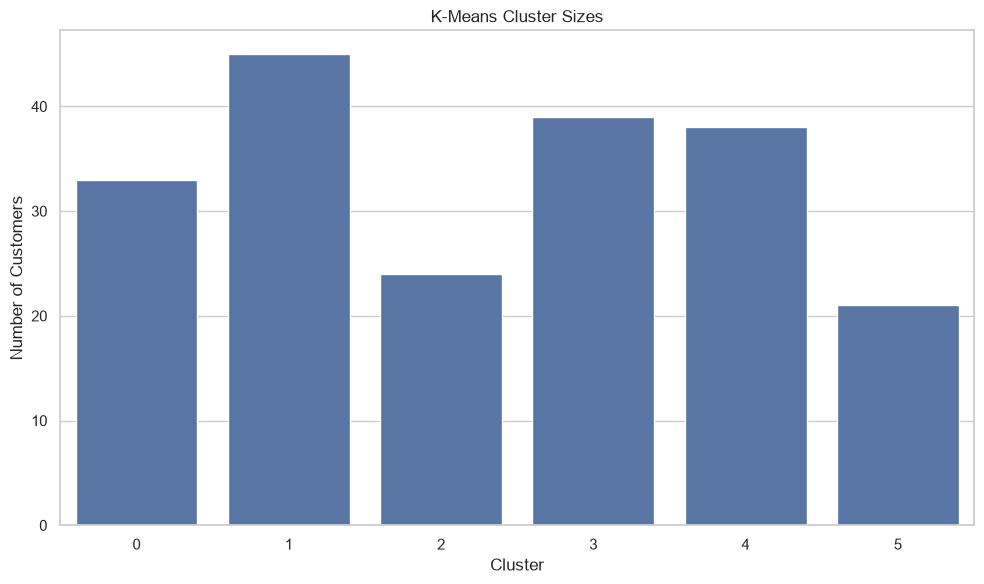

In [26]:
cluster_counts = (
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
)

display(cluster_counts.to_frame("Customer Count"))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("K-Means Cluster Sizes")
plt.tight_layout()
plt.show()


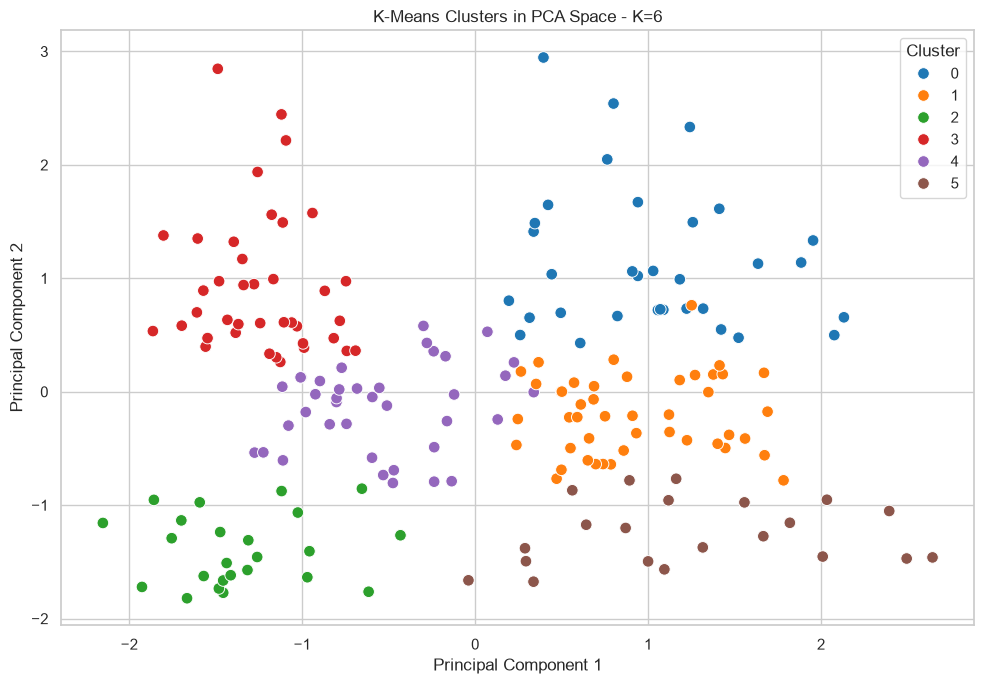

In [27]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette="tab10",
    s=70
)
plt.title(f"K-Means Clusters in PCA Space - K={final_k}")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


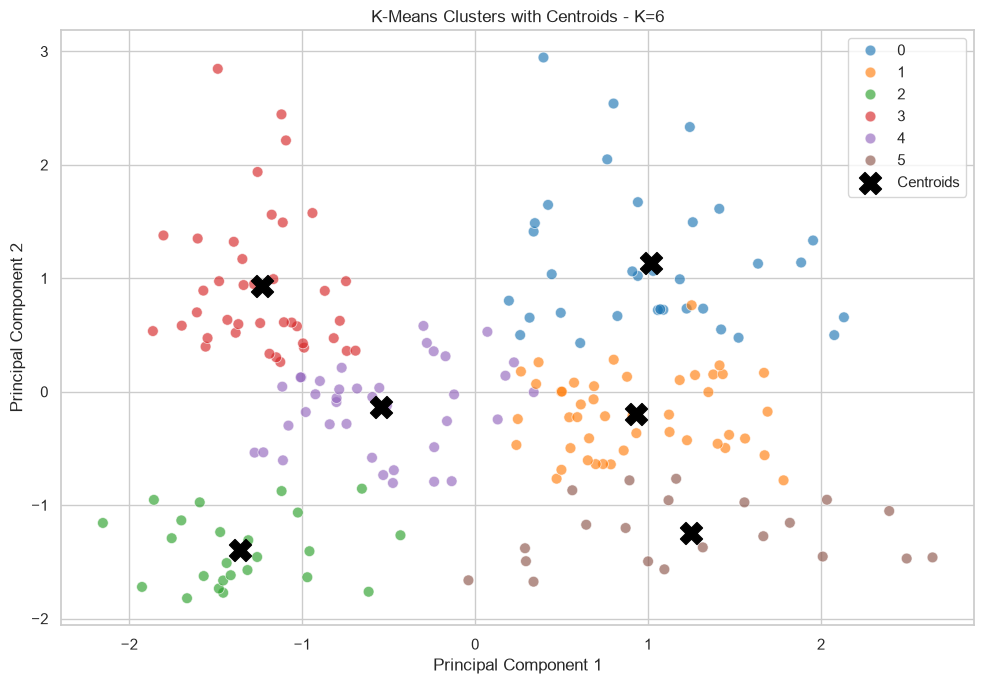

In [28]:
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette="tab10",
    s=60,
    alpha=0.65
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=250,
    c="black",
    label="Centroids"
)

plt.title(f"K-Means Clusters with Centroids - K={final_k}")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()


In [29]:
final_silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

final_calinski = calinski_harabasz_score(
    X_scaled,
    cluster_labels
)

final_davies = davies_bouldin_score(
    X_scaled,
    cluster_labels
)

final_inertia = kmeans.inertia_

final_metrics = pd.DataFrame({
    "Metric": [
        "Number of Clusters",
        "Inertia",
        "Silhouette Score",
        "Calinski-Harabasz Index",
        "Davies-Bouldin Index"
    ],
    "Value": [
        final_k,
        final_inertia,
        final_silhouette,
        final_calinski,
        final_davies
    ]
})

display(final_metrics)


,Metric,Value
0,Number of Clusters,6.000000
1,Inertia,133.868334
2,Silhouette Score,0.427428
3,Calinski-Harabasz Index,135.102217
4,Davies-Bouldin Index,0.827743
